# Review Text Analysis
Find out why customers leave bad reviews by reading the Portuguese comments.

In [1]:
import re
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.decomposition import NMF

pd.set_option("display.max_colwidth", 100)

In [2]:
path = "../Data/Processed/"
orders = pd.read_csv(path + "orders_clean.csv")
reviews = pd.read_csv(path + "reviews_by_order_clean.csv")

scope = orders[orders["in_analysis_scope"] == True][["order_id", "is_late"]]
rev = reviews.merge(scope, on="order_id")
total = len(rev)

rev = rev[rev["review_comment_message"].notna()].copy()
print(len(rev), "of", total, "reviews have a comment (", round(len(rev) / total * 100, 1), "% )")

38898 of 95824 reviews have a comment ( 40.6 % )


### Clean the text

In [3]:
def clean_text(text):
    text = str(text).lower()
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")  # nao / não -> nao
    text = re.sub(r"[^a-z ]", " ", text)
    return " ".join(text.split())

# kept "nao" out of this list since it flips the meaning
stopwords = ["a", "o", "as", "os", "e", "de", "da", "do", "das", "dos", "em", "no", "na", "nos", "nas",
             "um", "uma", "uns", "umas", "que", "com", "para", "pra", "por", "pelo", "pela", "se", "me", "meu",
             "minha", "eu", "ele", "ela", "foi", "ser", "esta", "estava", "isso", "este", "essa", "esse", "ao",
             "mas", "ou", "como", "mais", "ja", "so", "tem", "ter", "sao", "era", "q", "vc", "voce", "lhe",
             "sua", "seu", "ate", "quando", "muito", "bem", "the", "sim", "tambem", "fiz", "estou", "ainda"]

rev["clean"] = rev["review_comment_message"].apply(clean_text)
rev[["review_comment_message", "clean"]].head()

,review_comment_message,clean
2,"Amei a mesinha, que pena que me confundir na cor, comprei achando que seria branca, mas é nude. ...",amei a mesinha que pena que me confundir na cor comprei achando que seria branca mas e nude mas ...
6,O mocho não tem nem 6 meses de uso e a parte da estrutura já está rachando! Produto de péssima q...,o mocho nao tem nem meses de uso e a parte da estrutura ja esta rachando produto de pessima qual...
10,Muito bom,muito bom
12,recomendo,recomendo
13,òtimo,otimo


In [4]:
# 1-2 stars = negative, 4-5 = positive, 3 dropped
rev = rev[rev["review_score"] != 3].copy()
rev["negative"] = (rev["review_score"] <= 2).astype(int)
rev["negative"].value_counts()

negative
0    26233
1     9234
Name: count, dtype: int64

### Most common words in negative and positive reviews

In [5]:
glossary = {"produto": "product", "entrega": "delivery", "prazo": "deadline", "chegou": "arrived",
            "recebi": "received", "nao": "not", "atraso": "delay", "otimo": "great", "recomendo": "recommend",
            "excelente": "excellent", "bom": "good", "rapida": "fast", "rapido": "fast", "antes": "before",
            "qualidade": "quality", "loja": "store", "veio": "came", "comprei": "bought", "aguardando": "waiting",
            "entregue": "delivered", "dia": "day", "dias": "days", "pedido": "order", "certo": "right",
            "perfeito": "perfect", "gostei": "liked", "errado": "wrong", "defeito": "defect", "quebrado": "broken",
            "vendedor": "seller", "pessimo": "terrible", "ruim": "bad", "faltando": "missing", "compra": "purchase",
            "embalado": "packed", "tudo": "everything", "conforme": "as", "descricao": "description",
            "satisfeito": "satisfied", "agora": "now", "nada": "nothing", "contato": "contact",
            "correios": "post office", "atrasou": "was late", "gostaria": "would like", "unidade": "unit",
            "unidades": "units", "parabens": "congrats", "lindo": "beautiful", "chegaram": "arrived",
            "recebido": "received", "estrelas": "stars", "nota": "rating", "obrigado": "thanks"}

def eng(phrase):
    return " ".join(glossary.get(w, w) for w in phrase.split())

def top_words(texts, n=15):
    cv = CountVectorizer(stop_words=stopwords)
    counts = pd.Series(cv.fit_transform(texts).sum(axis=0).A1, index=cv.get_feature_names_out())
    counts = counts.sort_values(ascending=False).head(n)
    return pd.DataFrame({"word": counts.index, "english": [eng(w) for w in counts.index], "count": counts.values})

top_words(rev[rev["negative"] == 1]["clean"])

,word,english,count
0,nao,not,6804
1,produto,product,5106
2,recebi,received,2784
3,comprei,bought,1699
4,veio,came,1510
5,entregue,delivered,1138
6,entrega,delivery,1115
7,chegou,arrived,1038
8,prazo,deadline,736
9,compra,purchase,669


In [6]:
top_words(rev[rev["negative"] == 0]["clean"])

,word,english,count
0,produto,product,10535
1,prazo,deadline,7014
2,antes,before,5247
3,entrega,delivery,4591
4,chegou,arrived,3984
5,bom,good,3975
6,recomendo,recommend,3839
7,otimo,great,2355
8,entregue,delivered,2150
9,qualidade,quality,2144


### Can the words alone tell a bad review from a good one?

In [7]:
X_train, X_test, y_train, y_test = train_test_split(rev["clean"], rev["negative"], test_size=0.25,
                                                    stratify=rev["negative"], random_state=42)

tfidf = TfidfVectorizer(stop_words=stopwords, ngram_range=(1, 2), min_df=3)
X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, prob >= 0.5, target_names=["positive", "negative"]))
print("ROC AUC:", round(roc_auc_score(y_test, prob), 3))

              precision    recall  f1-score   support

    positive       0.98      0.92      0.95      6558
    negative       0.80      0.94      0.87      2309

    accuracy                           0.92      8867
   macro avg       0.89      0.93      0.91      8867
weighted avg       0.93      0.92      0.93      8867

ROC AUC: 0.972


### Which words push a review towards negative or positive?

In [8]:
coefs = pd.Series(model.coef_[0], index=tfidf.get_feature_names_out()).sort_values()

neg_words = coefs.tail(15)[::-1]
pd.DataFrame({"phrase": neg_words.index, "english": [eng(p) for p in neg_words.index], "weight": neg_words.values.round(2)})

,phrase,english,weight
0,nao,not,9.35
1,comprei,bought,4.89
2,nao recomendo,not recommend,4.57
3,aguardando,waiting,3.91
4,pessima,pessima,3.90
5,diferente,diferente,3.88
6,faltando,missing,3.53
7,pessimo,terrible,3.53
8,quero,quero,3.52
9,ruim,bad,3.51


In [9]:
pos_words = coefs.head(15)
pd.DataFrame({"phrase": pos_words.index, "english": [eng(p) for p in pos_words.index], "weight": pos_words.values.round(2)})

,phrase,english,weight
0,antes,before,-5.68
1,recomendo,recommend,-5.47
2,tudo,everything,-4.69
3,rapida,fast,-4.39
4,parabens,congrats,-4.36
5,rapido,fast,-4.34
6,excelente,excellent,-4.33
7,otimo,great,-4.29
8,boa,boa,-4.14
9,otima,otima,-4.09


### What do unhappy customers complain about?

In [10]:
neg_text = rev[rev["negative"] == 1]["clean"]

tfidf_neg = TfidfVectorizer(stop_words=stopwords, min_df=3, max_df=0.9)
X_neg = tfidf_neg.fit_transform(neg_text)

nmf = NMF(n_components=5, random_state=42, max_iter=500)
weights = nmf.fit_transform(X_neg)
words = tfidf_neg.get_feature_names_out()

for i, topic in enumerate(nmf.components_):
    top = [words[j] for j in topic.argsort()[::-1][:8]]
    print(f"Theme {i + 1}:", ", ".join(top), "|", eng(" ".join(top)))

Theme 1: recebi, nao, produto, momento, agora, avaliar, mercadoria, paguei | received not product momento now avaliar mercadoria paguei
Theme 2: chegou, produto, nao, qualidade, gostei, quebrado, loja, recomendo | arrived product not quality liked broken store recommend
Theme 3: comprei, veio, dois, apenas, produtos, outro, duas, unidades | bought came dois apenas produtos outro duas units
Theme 4: entregue, produto, nao, momento, consta, pedido, site, porem | delivered product not momento consta order site porem
Theme 5: entrega, prazo, dia, demora, aguardando, agora, hoje, atraso | delivery deadline day demora waiting now hoje delay


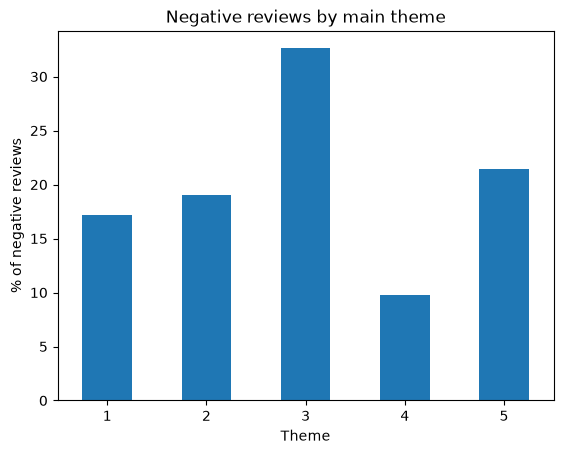

,reviews,share_%
1,1585,17.2
2,1753,19.0
3,3012,32.6
4,909,9.8
5,1975,21.4


In [11]:
themes = pd.Series(weights.argmax(axis=1) + 1).value_counts().sort_index()
share = (themes / themes.sum() * 100).round(1)

share.plot(kind="bar", rot=0)
plt.title("Negative reviews by main theme")
plt.xlabel("Theme")
plt.ylabel("% of negative reviews")
plt.show()

pd.DataFrame({"reviews": themes, "share_%": share})

### How many comments are about delivery?

In [12]:
rev["about_delivery"] = rev["clean"].str.contains(r"entreg|cheg|prazo|atras|receb|correio").astype(int)
rev.groupby("negative")["about_delivery"].mean().round(3)

negative
0    0.493
1    0.646
Name: about_delivery, dtype: float64

In [13]:
neg = rev[rev["negative"] == 1]
neg.groupby("is_late")["about_delivery"].agg(reviews="count", share="mean").round(3)

,reviews,share
is_late,,
False,6487,0.565
True,2747,0.838


In [14]:
neg[neg["about_delivery"] == 1][["review_score", "is_late", "review_comment_message"]].sample(5, random_state=1)

,review_score,is_late,review_comment_message
69005,2,False,"Pedido atendido parcialmente. Comprei três produtos, mas somente um dos itens foi entregue ."
46969,1,False,Espero obter uma resposta para minha encomenda. Comprei 3 controles remotos para ar condicionado...
70873,1,False,"Efetuei a compra de duas cortinas, mas recebi somente uma."
37670,1,True,"não recomendo pois não entregou no prazo e não consigo falar com eles, é muito ruim a targaryen"
7628,1,True,"Ola boa noite , produto não foi entregue ?"


## Observations

- Reviews with a comment: 38,898 of 95,824 (40.6%)
- After dropping 3-star reviews: 9,234 negative (1–2 stars) and 26,233 positive (4–5 stars)
- Common words in negative reviews: nao (not), produto (product), recebi (received), comprei (bought), veio (came), entregue (delivered), entrega (delivery), chegou (arrived), prazo (deadline)
- Common words in positive reviews: produto (product), prazo (deadline), antes (before), entrega (delivery), chegou (arrived), bom (good), recomendo (recommend), otimo (great), qualidade (quality)
- Text model ROC AUC: 0.972, recall for negative: 0.94 (precision 0.80). The words alone separate bad and good reviews very well.
- Strongest negative phrases: nao (not), nao recomendo (don't recommend), aguardando (waiting), pessima / pessimo (terrible), diferente (different), faltando (missing), ruim (bad), nao recebi (not received), quebrado (broken)
- Strongest positive phrases: antes (before), recomendo (recommend), tudo (everything), rapida / rapido (fast), parabens (congrats), excelente (excellent), otimo (great), perfeito (perfect), adorei / amei (loved)
- Theme 1 – Product not received (17.2% of negative reviews)
- Theme 2 – Poor quality or broken product (19.0%)
- Theme 3 – Missing or wrong items, e.g. bought two but only one came (32.6%, the largest theme)
- Theme 4 – Order shown as delivered on the website but not received (9.8%)
- Theme 5 – Delivery delay and waiting (21.4%)
- Three of the five themes (1, 4 and 5) are about delivery, covering 48.4% of negative reviews. Missing or wrong items add another 32.6%, so most complaints are about getting the right order on time, not about the product itself.
- 64.6% of negative comments mention delivery vs 49.3% of positive ones (positive comments often praise early delivery, e.g. "chegou antes do prazo", arrived before the deadline)
- Among negative reviews: 83.8% of late orders vs 56.5% of on-time orders mention delivery
- Business takeaway: the biggest complaint is incomplete or wrong orders, so checking items before dispatch, especially for multi-item orders, should be a priority next to late delivery. Orders marked as delivered but not received point to tracking or carrier problems worth investigating. Positive reviews often mention delivery that is fast or early, so realistic delivery estimates that Olist can beat would help reviews.
- Limitations: only 40.6% of reviews have a comment, and unhappy customers may be more likely to write one; translations are simple; theme names are my own reading of the top words.